<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Bootstrapping, Bagging, and Ensembling

_Author:_ Tim Book

### Learning Objectives
- Define and execute bootstrapping
- Fit and evaluate bagged decision trees
- Define ensemble models
- Use `sklearn` to manually ensemble models

In [105]:
# Import libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import BaggingClassifier, VotingClassifier

## Load the Data

We'll be using the `Heart.csv` from the [ISLR Website](https://www.statlearning.com/). There's a copy in this repo under `./datasets/Heart.csv`.

In [26]:
# Read in the Heart .csv data.
df = pd.read_csv('datasets/Heart.csv')

# Check the first few rows.
df.head()

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


## Data Cleaning & Model Prep

In [27]:
# Drop the `Unnamed: 0` column.
df.drop('Unnamed: 0', axis=1, inplace=True)

In [28]:
# Drop NAs.
# There are only a few, but for the sake of time let's just drop them.
df.dropna(inplace=True)

# Bootstrapping Exercise
Use the bootstrapping technique to estimate the distribution of the median cholesterol level of patients.

In [67]:
chol = df['Chol']
n = len(chol)
B = 500

In [68]:
boot_samples = [np.median(np.random.choice(chol, size=n, replace=True)) for _ in range(B)]

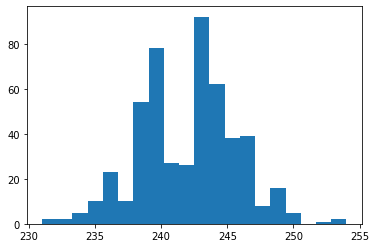

In [69]:
plt.hist(boot_samples, bins=20);

In [70]:
np.mean(boot_samples)

242.084

In [71]:
np.median(chol)

243.0

# Now You:
Let's create our `X` and `y` in the usual (fast, maybe sloppy) way. We'll use every x-variable we can, dummifying when needed.

Remember to binarize `y`!

In [29]:
# Create dummies for the `ChestPain`, `Thal`, and `AHD` columns.
# Be sure to set `drop_first=True`.
X = pd.get_dummies(
    df.drop(columns='AHD'),
    columns=['ChestPain', 'Thal'],
    drop_first=True
)

y = df['AHD'].map({'Yes': 1, 'No': 0})

In [32]:
y.mean()

0.4612794612794613

In [142]:
# Split data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.6, random_state=42)

Our target column will be `AHD_Yes`: 
- 1 means the patient has heart disease
- 0 means they aren't diagnosed with heart disease

In [143]:
# What is the accuracy of our baseline model?
y.value_counts(normalize=True)

0    0.538721
1    0.461279
Name: AHD, dtype: float64

What does a false positive mean in this case? False negative? Which is worse?

In [144]:
# Let's fit our "dumb" model - an overfit decision tree
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

DecisionTreeClassifier()

In [145]:
print(tree.score(X_train, y_train))
print(tree.score(X_test, y_test))

1.0
0.7563025210084033


# Let's bag it!

In [146]:
tree = DecisionTreeClassifier()
bag = BaggingClassifier(tree, n_estimators=100, random_state=2022)

In [147]:
bag.fit(X_train, y_train)

BaggingClassifier(base_estimator=DecisionTreeClassifier(), n_estimators=100,
                  random_state=2022)

In [148]:
print(bag.score(X_train, y_train))
print(bag.score(X_test, y_test))

0.9943820224719101
0.7983193277310925


# A model of a model of a model
We can even gridsearch over our bagged classifier to see if our ensemble benefits from having a "smart" or "dumb" base classifier.

In [149]:
pgrid = {
    'base_estimator__max_depth': np.append(np.arange(1, 8), None),
    'base_estimator__min_samples_leaf': np.arange(1, 12, 2)
    
}

tree = DecisionTreeClassifier()
bag = BaggingClassifier(base_estimator=tree, n_estimators=100, random_state=2022)
gs = GridSearchCV(bag, pgrid, cv=5, n_jobs=4)

In [150]:
%%time
# Q: How many total decision trees am I fitting?
gs.fit(X_train, y_train)

CPU times: user 1.25 s, sys: 31.2 ms, total: 1.28 s
Wall time: 10.3 s


GridSearchCV(cv=5,
             estimator=BaggingClassifier(base_estimator=DecisionTreeClassifier(),
                                         n_estimators=100, random_state=2022),
             n_jobs=4,
             param_grid={'base_estimator__max_depth': array([1, 2, 3, 4, 5, 6, 7, None], dtype=object),
                         'base_estimator__min_samples_leaf': array([ 1,  3,  5,  7,  9, 11])})

In [151]:
gs.best_params_

{'base_estimator__max_depth': 4, 'base_estimator__min_samples_leaf': 7}

In [152]:
print(gs.score(X_train, y_train))
print(gs.score(X_test, y_test))

0.9213483146067416
0.8067226890756303


In [153]:
pd.DataFrame(gs.cv_results_).sort_values('mean_test_score', ascending=False)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_base_estimator__max_depth,param_base_estimator__min_samples_leaf,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
21,0.157257,0.006836,0.011547,0.000436,4,7,"{'base_estimator__max_depth': 4, 'base_estimat...",0.750000,0.861111,0.722222,0.885714,0.800000,0.803810,0.062543,1
39,0.155299,0.005124,0.011372,0.000430,7,7,"{'base_estimator__max_depth': 7, 'base_estimat...",0.750000,0.861111,0.722222,0.857143,0.800000,0.798095,0.055734,2
33,0.151454,0.005129,0.011252,0.000608,6,7,"{'base_estimator__max_depth': 6, 'base_estimat...",0.750000,0.861111,0.722222,0.857143,0.800000,0.798095,0.055734,2
45,0.157542,0.004980,0.012506,0.001467,None,7,"{'base_estimator__max_depth': None, 'base_esti...",0.750000,0.861111,0.722222,0.857143,0.800000,0.798095,0.055734,2
27,0.155927,0.005598,0.011709,0.000434,5,7,"{'base_estimator__max_depth': 5, 'base_estimat...",0.750000,0.861111,0.722222,0.857143,0.800000,0.798095,0.055734,2
14,0.156904,0.009308,0.011432,0.000481,3,5,"{'base_estimator__max_depth': 3, 'base_estimat...",0.722222,0.805556,0.750000,0.857143,0.828571,0.792698,0.049790,6
20,0.153501,0.006096,0.011644,0.000667,4,5,"{'base_estimator__max_depth': 4, 'base_estimat...",0.722222,0.805556,0.750000,0.857143,0.828571,0.792698,0.049790,6
15,0.157714,0.007124,0.011709,0.000370,3,7,"{'base_estimator__max_depth': 3, 'base_estimat...",0.750000,0.833333,0.722222,0.885714,0.771429,0.792540,0.059238,8
13,0.155048,0.003690,0.011345,0.000518,3,3,"{'base_estimator__max_depth': 3, 'base_estimat...",0.722222,0.805556,0.750000,0.828571,0.828571,0.786984,0.043280,9
26,0.158601,0.003832,0.011843,0.000160,5,5,"{'base_estimator__max_depth': 5, 'base_estimat...",0.722222,0.805556,0.750000,0.828571,0.828571,0.786984,0.043280,9


# Ensembling anything!
You can also ensemble models of any general architecture. Let's try to do this with all the classification models we know so far!

In [156]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [157]:
lr = LogisticRegression(penalty='none')
knn = KNeighborsClassifier(n_neighbors=7)
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=7)

In [160]:
vc = VotingClassifier([
    ('lr', lr),
    ('knn', knn),
    ('tree', tree)
])

In [161]:
vc.fit(X_train, y_train)

/home/tim/.local/lib/python3.6/site-packages/sklearn/linear_model/_logistic.py:764: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)


VotingClassifier(estimators=[('lr', LogisticRegression(penalty='none')),
                             ('knn', KNeighborsClassifier(n_neighbors=7)),
                             ('tree',
                              DecisionTreeClassifier(max_depth=4,
                                                     min_samples_leaf=7))])

In [162]:
vc.score(X_test, y_test)

0.8235294117647058